# Where is a loaded steel part strained?

You are operating the ODIN imaging instrument at ESS. Behind this page, a simulation of the instrument produces your
measurements; the files are in the ESS NeXus format, and the wavelength of each neutron is computed with the official
ESS software.

**Your mission.** You are an engineer in a team that designs steel parts for a wind turbine. A part carries a large
force: where, inside the steel, is the material strained, and by how much? A strain gauge glued on the surface only
tells what happens at the surface. Neutrons go through the steel, and the wavelength of a **Bragg edge** is set by the
distance between planes of atoms: if the load changes this distance by one part in ten thousand, the edge moves by one
part in ten thousand. Your job: measure a steel specimen in a load frame, without load and under load, deduce the
strain of its crystal lattice in its narrow middle and in its wide ends, and tell the team whether the steel behaves
as designed (the last questions).

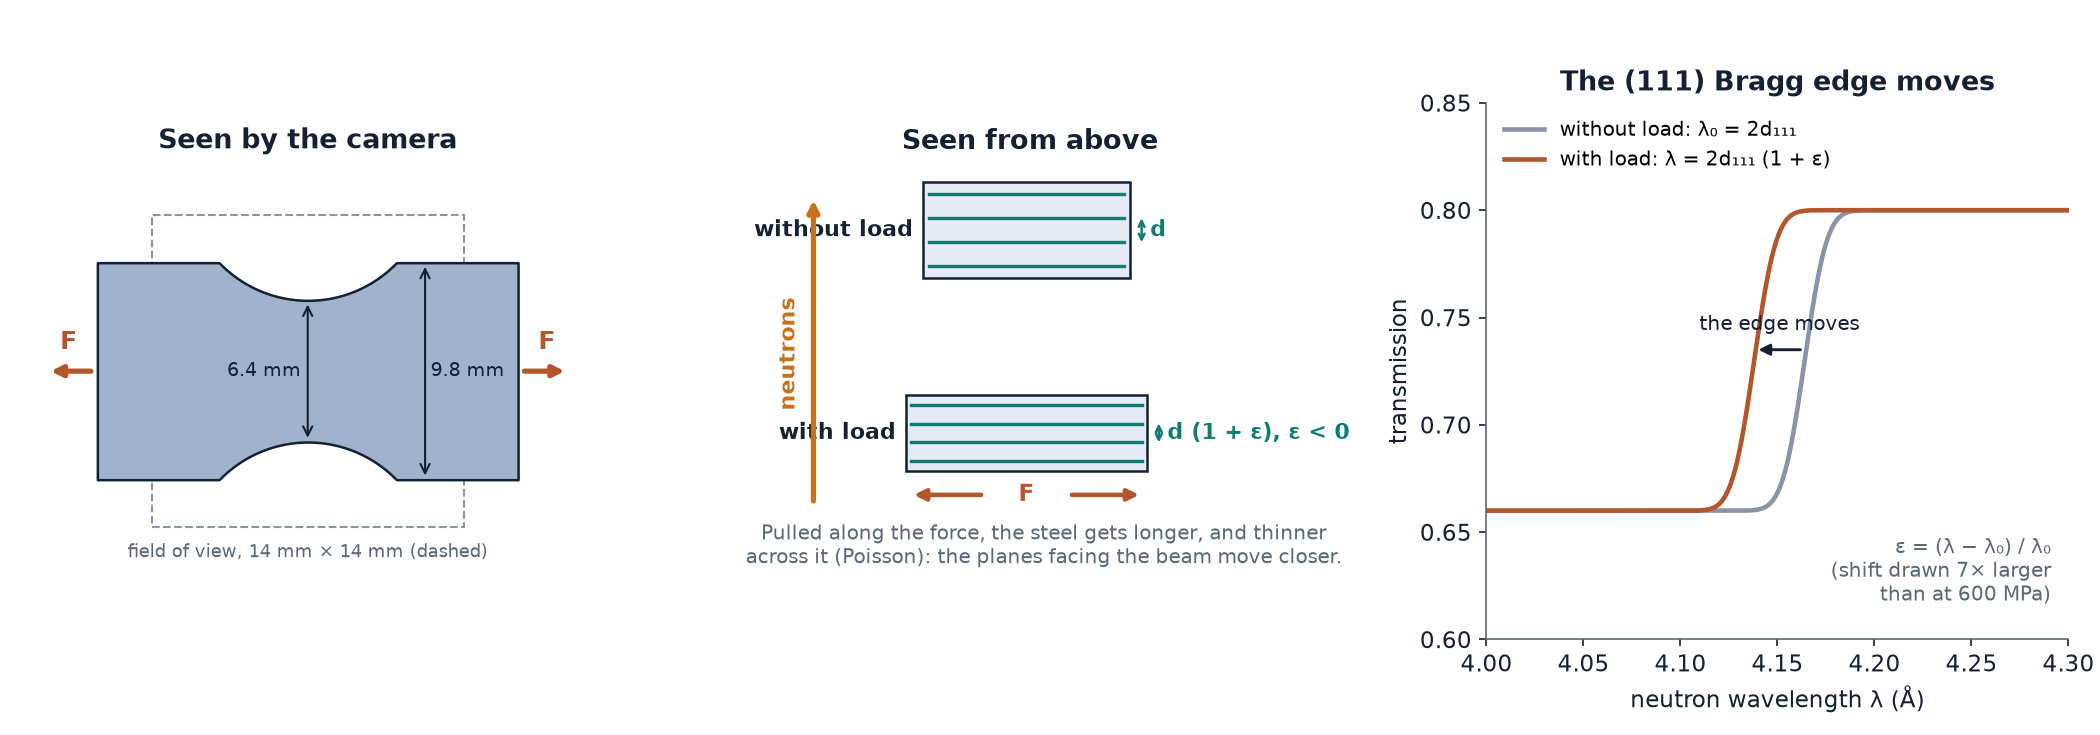

*The specimen in its load frame as the camera sees it (left); pulled along the force, the steel gets thinner across it, and the planes facing the beam move closer (middle); the Bragg edge of these planes moves to a shorter wavelength (right).*

**The specimen is real.** In September 2018, a tensile specimen of austenitic stainless steel was measured exactly this
way at V20, the test beamline of ESS at the HZB research reactor in Berlin (R. Woracek *et al.*, Nucl. Instrum.
Methods A 839, 102, 2016), without load and under 600 MPa. Its data are public (ESS, scipp/ess-notebooks-data). The
twin uses that specimen: its shape, its steel, its load. V20 needed **25 and 48 hours** of measurement to see the
strain; you will see how long ODIN needs.

**What you will measure.** A Bragg edge is the wavelength beyond which a family of planes can no longer scatter the
neutrons: $\lambda_\text{edge} = 2d$, with $d$ the distance between the planes. At the edge the neutrons are scattered
straight back, so the planes that count are those **facing the beam**. Under load $d$ becomes $d\,(1+\varepsilon)$,
and the edge moves from $\lambda_0$ to $\lambda$:

$$\varepsilon = \frac{\lambda - \lambda_0}{\lambda_0}$$

$\varepsilon$ is the **strain** of the lattice along the beam: a number without unit, here about $10^{-3}$.

**Questions along the page** check each step: answer in the box, then click *Check*. A wrong answer is explained;
after a try you can also show the answer. Your answers are kept.

In [ ]:
import sys, os, json, warnings
warnings.filterwarnings("ignore")
sys.path[:0] = [os.path.abspath("../../.."), os.path.abspath("../..")]     # twin/ and twin/odin/
import web_user
web_user.sign_in()            # the online version: the anonymous student of the start page (nothing to do in the app)
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, clear_output
from odin_virtual import VirtualOdin
import odin_viz as viz, odin_strain as strain
import sample_library as sl
from page_output import into
import quiz
q = quiz.Quiz("odin_steel_bsc")          # the questions, along the page

SAMPLE = "steel_tensile"
odin = VirtualOdin(session=os.environ.get("ODIN_SESSION", "student"))
odin.move(sample=SAMPLE)
F600 = 10.75                  # kN: 600 MPa in the narrowest section (6.4 mm × 2.8 mm)

## 0. Your specimen

A flat **tensile specimen** of austenitic stainless steel (type 304: iron with 19 % chromium and 11 % nickel; its
crystal is face-centered cubic), **2.8 mm thick**, held in a load frame that pulls it along $x$ (horizontal on the
camera) with a force $F$ that you choose. It is **9.8 mm wide**, narrowed in its middle to **6.4 mm** by two circular
arcs. The drawing shows it as the neutrons see it (left: the 14 mm field of view of the camera, dashed) and from above.

The same force crosses every section of the specimen. The **stress** is the force per unit of cross-section,
$\sigma = F / A$ (in MPa = N/mm²):

| Part | Width × thickness | Cross-section $A$ | Stress at 10.75 kN |
|---|---|---|---|
| middle (narrowest) | 6.4 mm × 2.8 mm | 17.9 mm² | 600 MPa |
| ends (wide) | 9.8 mm × 2.8 mm | 27.4 mm² | 392 MPa |

Below its elastic limit, steel comes back to its shape when the load is removed, and the strain is proportional to
the stress (Hooke's law): $\varepsilon_\text{load} = \sigma / E$ along the force, with $E$ ≈ 195 GPa for this steel.

In [ ]:
spec = odin.sample_spec(SAMPLE)
smp_out = w.Output()
with into(smp_out):
    sl.draw("odin", spec, fig=plt.figure(figsize=(10, 4)))
    sl.show()
display(smp_out)

In [ ]:
q.number("What is the stress in the narrowest section (6.4 mm × 2.8 mm) at 10.75 kN?", value=600, tol=10, unit="MPa",
         mistakes=[(392, "the stress in the wide ends (27.4 mm²); the middle has 17.9 mm²"),
                   (0.6, "in GPa (or kN/mm²); the answer is asked in MPa = N/mm²")],
         hints=["Stress = force / cross-section, with the force in N and the section in mm² to get MPa.",
                "10 750 N / (6.4 × 2.8) mm²."],
         explanation="σ = F/A = 10 750 N / 17.9 mm² = 600 MPa, the stress applied at V20.", title="Q1. The stress")

In [ ]:
q.number("With E = 195 GPa, which strain **along the force** does Hooke's law give in the narrowest section at 600 MPa? "
         "(in units of 10⁻³)", value=3.08, tol=0.08, unit="× 10⁻³",
         mistakes=[(0.00308, "right, but the answer is asked in units of 10⁻³: 3.08"),
                   (-0.89, "the strain along the beam; along the force it is σ/E, positive")],
         hints=["ε = σ / E, with σ and E in the same unit.", "σ = 600 MPa and E = 195 000 MPa."],
         explanation="ε = σ/E = 600 / 195 000 = 3.08 × 10⁻³: the middle of the specimen gets 0.3 % longer.",
         title="Q2. Hooke's law")

## 1. Operate the instrument

Set the controls, then click *Count*: the detector image and the spectrum of arrival times fill up during the count,
as on the instrument. A strain of $10^{-3}$ moves the edge by only 0.004 Å, so you need many neutrons: **repeat** each
measurement of the specimen and of the open beam **4 times** (60 s each); the analysis adds up the repeated counts.

| Measurement | Shutter | Stage x (mm) | Load | Time (s) | Repeat |
|---|---|---|---|---|---|
| 1. dark | **closed** | 0 | 0 | 60 | 1 |
| 2. open beam | **open** | **500** | 0 | 60 | **4** |
| 3. reference | open | **0** | **0 kN** | 60 | **4** |
| 4. under load | open | 0 | **10.75 kN** (600 MPa) | 60 | **4** |

Why these settings:
- the **choppers** are in WFM mode (wavelength frame multiplication, discs 0.30 m apart) and the **pinhole** is
  3 cm wide for all the measurements: WFM gives the sharp edges a shift of $10^{-3}$ needs, and the beam must be the
  same for all the measurements, so these settings are fixed here;
- **stage x = 500 mm** moves the specimen (with its load frame) aside, out of the field of view: the open beam;
- the **reference at 0 kN** is measured on the specimen itself, in the same position: the strain is the *change* of
  the edge, and everything else must stay the same;
- each count lasts as long as on the instrument, plus the time to compute it (about a minute): the 13 counts take
  about 25 minutes. Meanwhile, read the next parts.

In [ ]:
st = odin.status()
shut = w.ToggleButtons(options=[("closed", "closed"), ("open", "open")], value=st["shutter"], description="Shutter")
stage = w.BoundedFloatText(value=st["stage_x"] * 1000, min=-500, max=500, step=1, description="Stage x (mm)")
load = w.Dropdown(options=[("0 kN (no load)", 0.0), ("5.38 kN (300 MPa in the middle)", 5.38),
                           ("10.75 kN (600 MPa in the middle)", F600)], value=0.0, description="Load",
                  layout=w.Layout(width="420px"))
ttime = w.Dropdown(options=[30, 60], value=60, description="Time (s)")
title = w.Text(value="", placeholder="e.g. steel 0 kN", description="Title")
button = w.Button(description="Count", button_style="primary", icon="play", layout=w.Layout(width="auto"))
out = w.Output()

def do_count(_):
    button.disabled = True
    with out:
        clear_output()
        try:
            odin.move(choppers="wfm", wfm_delta=0.30, pinhole=0.03, diffuser="in", shutter=shut.value,
                      stage_x=stage.value / 1000, sample=SAMPLE, load=float(load.value))
            live = viz.LiveCount()                  # the image and the spectrum fill up during the count
            f = odin.count(ttime.value, title=title.value or default_title(), progress=live.update)
            live.done(f)
        except Exception as e:
            print("Error:", e)
    button.disabled = False
    refresh_list()

def default_title():
    if shut.value == "closed":
        return "dark"
    return "open beam" if abs(stage.value) > 20 else f"steel {load.value:g} kN"

button.on_click(do_count)
display(w.VBox([shut, stage, load, ttime, title, button, out]))

## 2. Your measurements

Each count produces a numbered file, as on the real instrument. The table recalls the state of the instrument during
each measurement (your logbook), and how the analysis groups them: the open beams together, and the counts of the
specimen at each load together.

In [ ]:
listing = w.Output()

def measurements():
    ms = []
    if os.path.isfile(odin.log_file):
        for l in open(odin.log_file, encoding="utf-8"):
            e = json.loads(l)
            if e["action"] == "count" and e["details"].get("file"):
                d = e["details"]; s = d["state"]
                kind = "dark" if s["shutter"] == "closed" else ("open beam" if abs(s["stage_x"]) > 0.02 else "specimen")
                if s.get("sample") != SAMPLE or not (s["choppers"] == "wfm" and abs(s["wfm_delta"] - 0.30) < 1e-6):
                    continue
                ms.append(dict(file=d["file"], path=os.path.join(odin.folder, d["file"]), title=d["title"], t=d["t"],
                               kind=kind, load=round(float(s.get("load") or 0), 2), counts=d["n_counts"]))
    return ms

def groups():
    ms = measurements()
    dark = [m["path"] for m in ms if m["kind"] == "dark"][-1:]
    ob = [m["path"] for m in ms if m["kind"] == "open beam"]
    by_load = {}
    for m in ms:
        if m["kind"] == "specimen":
            by_load.setdefault(m["load"], []).append(m["path"])
    return (dark[0] if dark else None), ob, by_load

def refresh_list():
    ms = measurements()
    with into(listing):
        if not ms:
            print("No measurement yet.")
        for m in ms:
            print(f"{m['file']}  {m['title'] or '(no title)':16s} {m['kind']:10s} t = {m['t']:3g} s  load = {m['load']:5g} kN"
                  f"  -> {m['counts']:,} counts")
        dk, ob, by = groups()
        if ms:
            print(f"\nanalysis: dark {'yes' if dk else 'no'}; open beam: {len(ob)} counts; specimen: "
                  + ", ".join(f"{k:g} kN × {len(v)}" for k, v in sorted(by.items())))

refresh_list()
display(listing)

## 3. The edge, without and with load

For each wavelength, the transmission of a region of the specimen is

$$T = \frac{E - N}{O - N}$$

with $E$, $O$ and $N$ the counts of the specimen, open-beam and dark runs in that region (all the repeated counts
added; the dark is scaled to the duration of each measurement, and each measurement is divided by the proton charge
received by the target).

*Fit the edge* draws the transmission of a region without load and under the largest load, around the last Bragg edge
of this steel, that of the (111) planes, near 4.16 Å. The edge is not a sharp step: the wavelength resolution of the
instrument smooths it over about 0.02 Å. Its position is found by **fitting** a smoothed step to all the points of
the edge: this is how a shift ten times smaller than the width of the edge can be measured. The first time a file is
used, reading its millions of neutrons takes about 20 s.

In [ ]:
region = w.Dropdown(options=list(strain.REGIONS), value="middle", description="Region", layout=w.Layout(width="420px"))
button_fit = w.Button(description="Fit the edge", button_style="success", icon="chart-line", layout=w.Layout(width="auto"))
out_fit = w.Output()

def chosen():
    dk, ob, by = groups()
    loads = sorted(k for k in by if k > 0)
    if not (ob and 0.0 in by and loads):
        raise ValueError("Measure first: open beams, the specimen without load (0 kN) and under load (part 1).")
    return dk, ob, by, loads[-1]

def fit_edge(_):
    button_fit.disabled = True
    with out_fit:
        clear_output()
        try:
            dk, ob, by, kN = chosen()
            print("Reading the files and fitting...")
            a, b = strain.edge(by[kN], ob, dk, region.value), strain.edge(by[0.0], ob, dk, region.value)
            e, de = strain.strain(a, b)
            clear_output()
            fig, ax = plt.subplots(figsize=(8.5, 4.6))
            strain.plot_edges(ax, a, b, kN, region.value)
            plt.tight_layout(); plt.show()
            print(f"{region.value}, {kN:g} kN ({len(by[kN])} counts; reference {len(by[0.0])} counts): "
                  f"stress = {strain.stress_MPa(kN, region.value):.0f} MPa")
            print(f"  edge without load: {b['lam_edge']:.4f} ± {b['dlam_edge']:.4f} Å")
            print(f"  edge under load  : {a['lam_edge']:.4f} ± {a['dlam_edge']:.4f} Å")
            print(f"  strain along the beam: ε = ({a['lam_edge']:.4f} − {b['lam_edge']:.4f}) / {b['lam_edge']:.4f} "
                  f"= ({e * 1e4:+.1f} ± {de * 1e4:.1f}) × 10⁻⁴")
            if dk is None:
                print("Note: no dark run, the background is not subtracted.")
        except Exception as err:
            clear_output()
            print("Not possible yet:", err)
    button_fit.disabled = False

button_fit.on_click(fit_edge)
display(w.VBox([region, button_fit, out_fit]))

In [ ]:
q.number("At which wavelength is the (111) edge of the specimen **without load** (part 3, middle)?",
         value=4.163, tol=0.012, unit="Å",
         mistakes=[(4.054, "the (110) edge of ferritic steel (α-iron); this steel is austenitic (fcc)"),
                   (2.082, "the distance d between the planes; the edge is at λ = 2d"),
                   (3.606, "the lattice parameter a; the (111) edge is at 2a/√3")],
         hints=["Part 3 prints it after the fit: 'edge without load'.", "It is between 4.15 and 4.18 Å."],
         explanation="The (111) planes of this steel are d = a/√3 = 3.606/1.732 = 2.082 Å apart, so the edge is at "
                     "2d = 4.164 Å (the value measured on the real specimen at V20).", title="Q3. The edge without load")

In [ ]:
q.choice("Why measure the specimen **without load** rather than use the textbook value of the edge?",
         ["The strain is a difference of 10⁻⁴: the alloy and the instrument shift the edge by as much or more, the same "
          "way in both measurements, so the difference removes it.",
          "The textbook value is for 0 K.",
          "To subtract the background of the detector.",
          "It is not needed: the textbook value would give the same strain."],
         answer=0, why={1: "Thermal expansion matters, but it is one of several shifts; what removes them all?",
                        2: "The background is removed by the dark run.",
                        3: "The lattice parameter of a stainless steel depends on its exact composition (3.59–3.61 Å): "
                           "that is 10 times the strain."},
         explanation="Austenitic steels have lattice parameters from 3.59 to 3.61 Å depending on their alloying, and the "
                     "shape of the neutron pulses shifts the fitted position: shifts far larger than the strain, but "
                     "identical with and without load. The difference removes them.",
         hints=["How well is the lattice parameter of 'a stainless steel' known?"], title="Q4. The reference")

In [ ]:
q.choice("The edge is about 0.02 Å wide and moves by 0.004 Å. How can such a small shift be measured?",
         ["A smoothed step is fitted to all the points of the edge: its position is known far better than its "
          "width, the better the more neutrons are counted.",
          "It cannot: a shift smaller than the width is not measurable.",
          "By using wavelength bins of 0.0001 Å.",
          "By reading the highest point of the edge."],
         answer=0, why={1: "You have just done it: look at the uncertainties of part 3.",
                        2: "Narrower bins hold fewer neutrons each: the noise grows, the information is the same.",
                        3: "A single point is noisy; the fit uses all of them."},
         explanation="The position of a known shape is found with a precision of about its width divided by the "
                     "square root of the number of neutrons that draw it.",
         hints=["How many points of the spectrum does the fit use?",
                "The mean of N values is known √N times better than one value."],
         title="Q5. Smaller than the resolution")

**Reading the result.** The edge under load is at a *shorter* wavelength: the strain along the beam is **negative**,
although the specimen is pulled. Pulled along the force, the steel gets longer, and thinner across it: this is the
Poisson effect, $\varepsilon_\text{across} = -\nu\,\varepsilon_\text{load}$, with $\nu$ (Poisson's ratio) about 0.3
for steel. The beam crosses the specimen *across* the force: the planes facing the beam move closer.

## 4. The strain map

*Map the strain* fits the edge in the three regions of the specimen (its middle and its two ends), without load and
under the largest load, and colors each region by its strain along the beam.

In [ ]:
button_map = w.Button(description="Map the strain", button_style="success", icon="th", layout=w.Layout(width="auto"))
out_map = w.Output()

def strains_of(files, ref, ob, dk):
    return {r: strain.strain(strain.edge(files, ob, dk, r), strain.edge(ref, ob, dk, r)) for r in strain.REGIONS}

def do_map(_):
    button_map.disabled = True
    with out_map:
        clear_output()
        try:
            dk, ob, by, kN = chosen()
            print("Reading the files and fitting the three regions...")
            res = strains_of(by[kN], by[0.0], ob, dk)
            clear_output()
            fig, ax = plt.subplots(figsize=(7.4, 5.2))
            fig.colorbar(strain.plot_map(ax, strain.transmission_image(by[kN], ob), res), ax=ax,
                         label="strain along the beam (10⁻³)")
            ax.set_title(f"Strain along the beam at {kN:g} kN (10⁻³)")
            plt.tight_layout(); plt.show()
            for r, (e, de) in res.items():
                print(f"{r:10s} stress {strain.stress_MPa(kN, r):4.0f} MPa   strain ({e * 1e4:+.1f} ± {de * 1e4:.1f}) × 10⁻⁴")
        except Exception as err:
            clear_output()
            print("Not possible yet:", err)
    button_map.disabled = False

button_map.on_click(do_map)
display(w.VBox([button_map, out_map]))

In [ ]:
q.choice("The transmission measurement gives the strain of the lattice in one direction only. Which one?",
         ["Along the beam: at the edge the neutrons are scattered straight back, by the planes facing the beam.",
          "Along the force: this is where the steel is stretched.",
          "The average over all directions.",
          "Along the width of the specimen (vertical, across the beam)."],
         answer=0, why={1: "The planes that set the edge are those facing the beam (back-scattering, λ = 2d): their "
                           "distance is measured along the beam, not along the force.",
                        2: "At the edge only one orientation of the planes scatters: the one facing the beam.",
                        3: "The planes that set the edge face the beam: their distance is measured along the beam."},
         explanation="λ_edge = 2d is Bragg's law for θ = 90°: back-scattering by the planes perpendicular to the beam. "
                     "The edge gives their distance, so the strain along the beam, across the thickness.",
         hints=["Bragg's law λ = 2d sin θ: which θ gives the largest λ, the edge?",
                "θ = 90°: the neutron comes straight back. How are the planes oriented with respect to the beam?"],
         title="Q6. Which strain?")

In [ ]:
q.number("Which strain **along the beam** did you measure in the middle at 10.75 kN (part 3 or 4)? (in units of 10⁻⁴, "
         "with its sign)", value=-8.8, tol=4.5, unit="× 10⁻⁴",
         mistakes=[(8.8, "the sign: the edge moved to a shorter wavelength, so the strain is negative"),
                   (30.8, "the strain along the force (Q2); the measurement gives the strain along the beam")],
         hints=["Part 3 prints it for the middle.", "It is negative, about −9 × 10⁻⁴."],
         explanation="Expected −ν σ/E = −0.29 × 594 / 195 000 = −8.8 × 10⁻⁴ in the middle region (594 MPa on average). "
                     "With 4 × 60 s per measurement your value has an uncertainty of about ± 3 × 10⁻⁴: yours is right "
                     "if it agrees within about twice this uncertainty. V20 measured −7.6 ± 3.0 × 10⁻⁴.",
         title="Q7. Your measurement")

In [ ]:
q.number("V20 needed 25 + 48 hours of measurement for an uncertainty of ± 3 × 10⁻⁴; you needed 8 minutes (4 × 60 s at "
         "each load). How many times faster is ODIN here?", value=550, tol=60,
         hints=["73 hours in minutes, divided by 8."],
         explanation="73 h = 4380 min, / 8 min ≈ 550. V20 imitated the ESS pulse on a research reactor, keeping only "
                     "about 4 % of its neutrons (2.86 ms every 71 ms); ODIN gets the full pulses of the spallation "
                     "source of ESS (here at its design power of 5 MW): hundreds of times more neutrons, with the same "
                     "WFM resolution.", title="Q8. ODIN and V20")

In [ ]:
q.choice("You want error bars on the strain **twice** smaller. How long should each measurement be?",
         ["4 times longer", "twice longer", "1.5 times longer", "the same, with narrower wavelength bins"],
         answer=0, why={1: "Twice the neutrons give errors √2 = 1.4 times smaller, not 2.",
                        2: "1.5 times the neutrons give errors 1.2 times smaller.",
                        3: "Fewer neutrons per bin: the same information."},
         explanation="Counting statistics: the uncertainty goes as 1/√N. Twice smaller needs 4 times the neutrons.",
         hints=["N counts have an uncertainty √N.", "1/√N twice smaller: N how many times larger?"],
         title="Q9. Counting time")

**A map with three regions only?** A region needs several mm² and many neutrons for a shift of $10^{-4}$. Real
strain maps have pixels well below a millimeter: they take hours of beam time per load. The principle is the same.

**Limits of the twin.** Each thin slice of the specimen has one uniform stress, $F/A$: in the real specimen the stress
changes progressively where the section changes, and is larger near the edges of the arcs (stress concentration).
The real specimen also has a texture (its grains are not oriented at random), which changes the heights of the edges,
not their positions.

## 5. Strain against stress

*Strain against stress* uses **all** your measurements under load and the three regions: each gives one point, the
strain along the beam against the stress $\sigma = F/A$ of the region. If the steel is elastic, all the points are on
one straight line through zero, of slope $-\nu / E$.

In [ ]:
button_line = w.Button(description="Strain against stress", button_style="success", icon="chart-line", layout=w.Layout(width="auto"))
out_line = w.Output()
E_GPA = 195.0

def do_line(_):
    button_line.disabled = True
    with out_line:
        clear_output()
        try:
            dk, ob, by, _ = chosen()
            loads = sorted(k for k in by if k > 0)
            print(f"Reading the files and fitting ({len(loads)} loads, three regions)...")
            pts = []
            for kN in loads:
                for r, (e, de) in strains_of(by[kN], by[0.0], ob, dk).items():
                    pts.append((strain.stress_MPa(kN, r), e, de, r, kN))
            x, y, dy = (np.array([p[k] for p in pts]) for k in range(3))
            a, da = strain.line_through_zero(x, y, dy)
            nu, dnu = -a * E_GPA * 1e3, da * E_GPA * 1e3
            clear_output()
            fig, ax = plt.subplots(figsize=(8, 4.8))
            for r, c, mk in (("middle", "tab:red", "o"), ("left end", "tab:blue", "<"), ("right end", "tab:blue", ">")):
                k = [i for i, p in enumerate(pts) if p[3] == r]
                ax.errorbar(x[k], y[k] * 1e4, yerr=dy[k] * 1e4, fmt=mk, color=c, capsize=3, label=r)
            xs = np.array([0, max(x) * 1.08])
            ax.plot(xs, a * xs * 1e4, "k-", lw=1.2, label=f"line through zero: slope ({a * 1e6:.2f} ± {da * 1e6:.2f}) × 10⁻⁶ per MPa")
            ax.plot(0, 0, "ks", ms=5)
            ax.set(xlabel="stress σ = F / A (MPa)", ylabel="strain along the beam (10⁻⁴)", title="Strain against stress")
            ax.grid(alpha=0.3); ax.legend(fontsize=9)
            plt.tight_layout(); plt.show()
            print(f"slope = −ν / E = ({a * 1e6:.2f} ± {da * 1e6:.2f}) × 10⁻⁶ per MPa")
            print(f"with E = {E_GPA:.0f} GPa = {E_GPA * 1e3:.0f} MPa:  ν = −slope × E = {nu:.2f} ± {dnu:.2f}")
        except Exception as err:
            clear_output()
            print("Not possible yet:", err)
    button_line.disabled = False

button_line.on_click(do_line)
display(w.VBox([button_line, out_line]))

In [ ]:
q.number("Which Poisson's ratio ν do your measurements give (part 5)?", value=0.29, tol=0.2,
         mistakes=[(-0.29, "the sign: ν = −slope × E is positive")],
         hints=["Part 5 prints it: ν = −slope × E.", "For steel it is close to 0.3; your uncertainty is large."],
         explanation="ν ≈ 0.29 for this steel. With one load and three regions your value is uncertain by about ± 0.1: "
                     "more loads and longer counts would tighten it.", title="Q10. Poisson's ratio")

In [ ]:
q.choice("**Your verdict for the team.** What do your measurements show?",
         ["Under 600 MPa the lattice contracts across the specimen by about 10⁻³ in the middle, less in the wide ends: "
          "the strain follows the stress, as elasticity predicts with ν ≈ 0.3.",
          "The middle has yielded: its strain is larger than that of the ends.",
          "The strain is the same everywhere: the force is the same in every section.",
          "Nothing: the shifts are within the error bars."],
         answer=0, why={1: "A larger strain is what elasticity predicts for a smaller cross-section (a larger stress).",
                        2: "The force is the same, but not the stress: the middle has a smaller cross-section.",
                        3: "In the middle the shift is about 3 times its uncertainty: detected, as at V20."},
         explanation="The strain is proportional to the stress, the same law in the middle and in the ends: the "
                     "signature of elastic behavior, as found at V20 (−7.6 ± 3.0 × 10⁻⁴ for −8.6 × 10⁻⁴ expected).",
         hints=["Look at part 5: are the points on one line through zero?",
                "Same force, different cross-sections: how do the stresses compare?"],
         title="Q11. The verdict")

## 6. Your results

Your score on the questions of the page, and a report to download.

In [ ]:
q.report()

## 7. Submit your work

When you are done, tell what you thought of the exercise and submit your work.

In [ ]:
import submit
_ = submit.Submit("odin/exercises/steel_strain", "bsc", quiz=q)